In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings
warnings.filterwarnings('ignore')

from torch_geometric.nn import GCNConv
from torch_geometric.utils import negative_sampling
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style("whitegrid")

Device: cuda


---
## 1. Exploration des donnees

In [2]:
# Charger les profils Pokec
profiles = pd.read_csv(
    'pokec/soc-pokec-profiles.txt.gz', sep='\t', header=None,
    na_values=['null'], index_col=False,
    names=[
        'user_id','public','completion_percentage','gender','region',
        'last_login','registration','AGE','body','I_am_working_in_field',
        'spoken_languages','hobbies','I_most_enjoy_good_food','pets',
        'body_type','my_eyesight','eye_color','hair_color','hair_type',
        'completed_level_of_education','favourite_color',
        'relation_to_smoking','relation_to_alcohol','sign_in_zodiac',
        'on_pokec_i_am_looking_for','love_is_for_me',
        'relation_to_casual_sex','my_partner_should_be','marital_status',
        'children','relation_to_children','I_like_movies',
        'I_like_watching_movie','I_like_music',
        'I_mostly_like_listening_to_music','the_idea_of_good_evening',
        'I_like_specialties_from_kitchen','fun','I_am_going_to_concerts',
        'my_active_sports','my_passive_sports','profession',
        'I_like_books','life_style','music','cars','politics',
        'relationships','art_culture','hobbies_interests',
        'science_technologies','computers_internet','education','sport',
        'movies','travelling','health','companies_brands','more','photo_count'
    ]
)
print(f"Profils charges: {len(profiles)}")
print(f"Colonnes: {profiles.shape[1]}")
profiles.head(3)

Profils charges: 1632803
Colonnes: 60


,user_id,public,completion_percentage,gender,region,last_login,registration,AGE,body,I_am_working_in_field,...,science_technologies,computers_internet,education,sport,movies,travelling,health,companies_brands,more,photo_count
0,1,1,14,1.0,"zilinsky kraj, zilina",2012-05-25 11:20:00.0,2005-04-03 00:00:00.0,26.0,"185 cm, 90 kg",it,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1,62,0.0,"zilinsky kraj, kysucke nove mesto",2012-05-25 23:08:00.0,2007-11-30 00:00:00.0,0.0,"166 cm, 58 kg",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,16,1,64,1.0,"zilinsky kraj, kysucke nove mesto",2012-05-25 23:19:40.0,2008-05-18 00:00:00.0,23.0,"173 cm, 70 kg",najvatcsej firme na svete urad prace,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Filtrer sur bratislavsky kraj
REGION = 'bratislavsky kraj'
profiles['region'] = profiles['region'].astype(str)
df = profiles[profiles['region'].str.startswith(REGION, na=False)].copy()

# Nettoyage genre et age
for c in ['gender', 'AGE', 'completion_percentage', 'public']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df[df['gender'].isin([0, 1]) & (df['AGE'] > 0) & (df['AGE'] < 100)].copy()
df['gender'] = df['gender'].astype(int)

print(f"Profils dans {REGION}: {len(df)}")
print(f"Genre: F(0)={( df['gender']==0).sum()}, H(1)={(df['gender']==1).sum()}")
print(f"Age: min={df['AGE'].min()}, max={df['AGE'].max()}, mean={df['AGE'].mean():.1f}, median={df['AGE'].median():.0f}")

Profils dans bratislavsky kraj: 123312
Genre: F(0)=58728, H(1)=64584
Age: min=1.0, max=99.0, mean=26.6, median=25


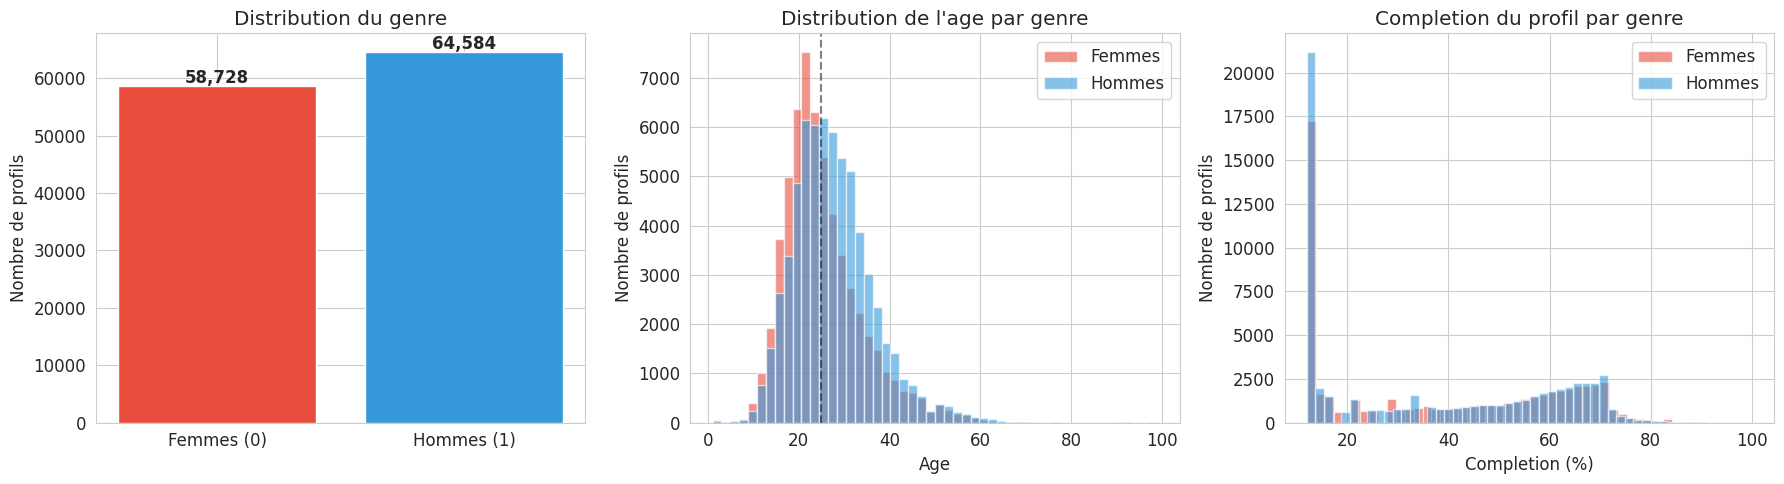

In [4]:
# Visualisation: distribution du genre et de l'age
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Genre
gender_counts = df['gender'].value_counts().sort_index()
axes[0].bar(['Femmes (0)', 'Hommes (1)'], gender_counts.values, color=['#e74c3c', '#3498db'])
axes[0].set_title('Distribution du genre')
axes[0].set_ylabel('Nombre de profils')
for i, v in enumerate(gender_counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Age
axes[1].hist(df[df['gender']==0]['AGE'], bins=50, alpha=0.6, label='Femmes', color='#e74c3c')
axes[1].hist(df[df['gender']==1]['AGE'], bins=50, alpha=0.6, label='Hommes', color='#3498db')
axes[1].set_title('Distribution de l\'age par genre')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Nombre de profils')
axes[1].legend()
axes[1].axvline(25, color='black', linestyle='--', alpha=0.5, label='Seuil 25 ans')

# Completion percentage
axes[2].hist(df[df['gender']==0]['completion_percentage'], bins=50, alpha=0.6, label='Femmes', color='#e74c3c')
axes[2].hist(df[df['gender']==1]['completion_percentage'], bins=50, alpha=0.6, label='Hommes', color='#3498db')
axes[2].set_title('Completion du profil par genre')
axes[2].set_xlabel('Completion (%)')
axes[2].set_ylabel('Nombre de profils')
axes[2].legend()

plt.tight_layout()
plt.savefig('fig_exploration_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

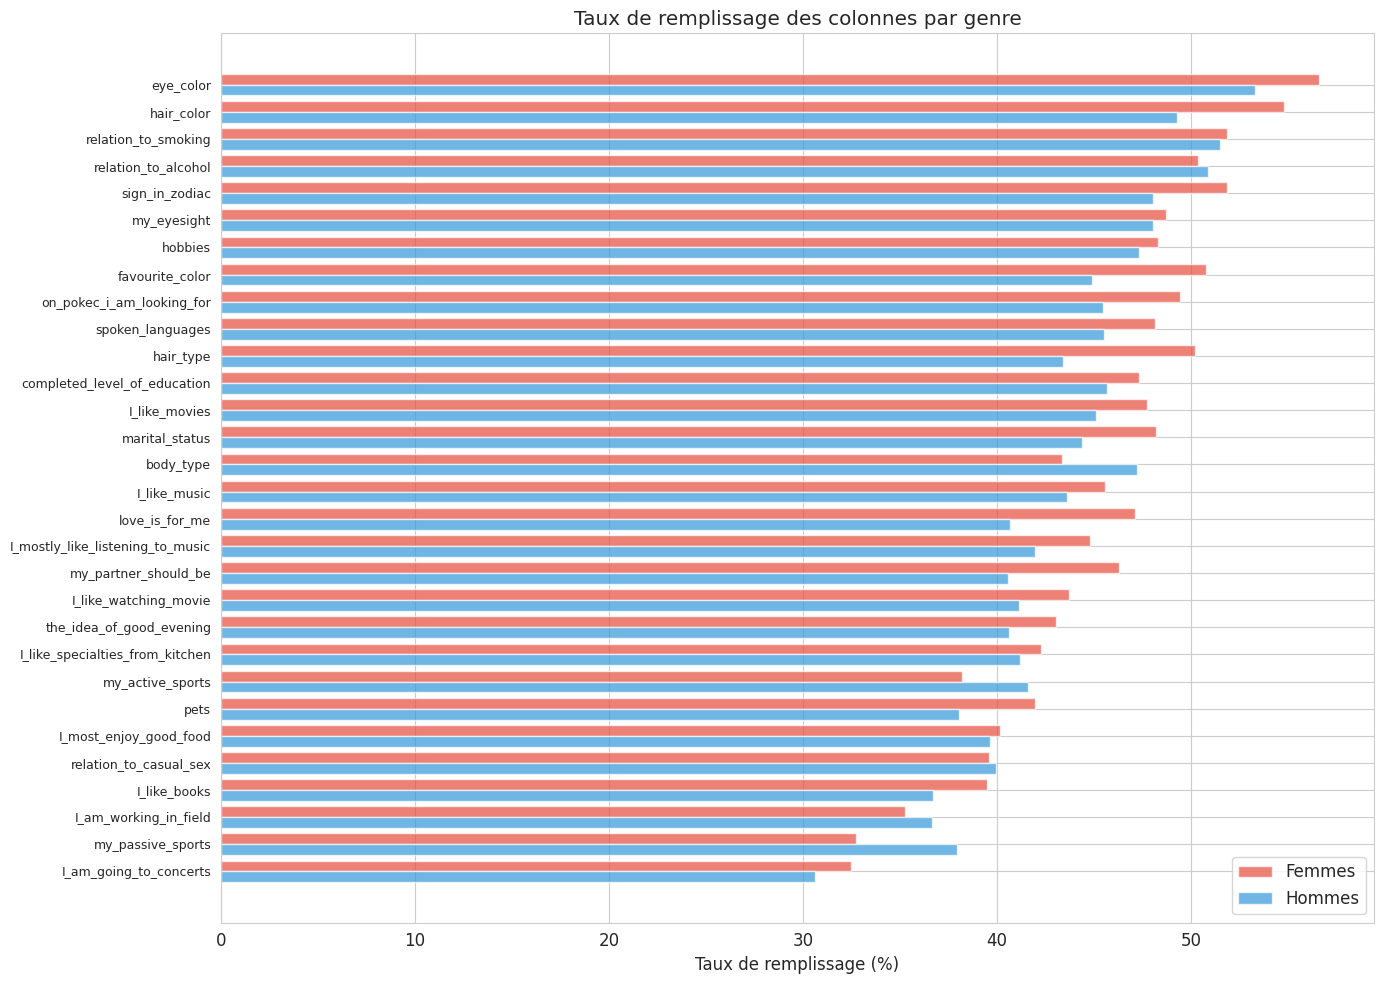

Top differences de remplissage F-H:
                  Colonne  Femmes (%)  Hommes (%)  Total (%)  Diff F-H
                hair_type   50.190710   43.416326  46.642663  6.774384
           love_is_for_me   47.091677   40.681903  43.734592  6.409774
          favourite_color   50.749217   44.870247  47.670138  5.878970
     my_partner_should_be   46.308405   40.556485  43.295867  5.751920
               hair_color   54.786473   49.249040  51.886272  5.537433
        my_passive_sports   32.742474   37.918060  35.453159 -5.175586
on_pokec_i_am_looking_for   49.409140   45.464821  47.343324  3.944319
                     pets   41.957840   38.045027  39.908525  3.912813
                body_type   43.323457   47.212932  45.360549 -3.889475
           sign_in_zodiac   51.876447   48.018085  49.855651  3.858362


In [5]:
# Analyse du taux de remplissage des colonnes textuelles par genre
TEXT_COLS = [
    'I_am_working_in_field', 'spoken_languages', 'hobbies',
    'I_most_enjoy_good_food', 'pets', 'body_type', 'my_eyesight',
    'eye_color', 'hair_color', 'hair_type',
    'completed_level_of_education', 'favourite_color',
    'relation_to_smoking', 'relation_to_alcohol', 'sign_in_zodiac',
    'on_pokec_i_am_looking_for', 'love_is_for_me',
    'relation_to_casual_sex', 'my_partner_should_be', 'marital_status',
    'I_like_movies', 'I_like_watching_movie', 'I_like_music',
    'I_mostly_like_listening_to_music', 'the_idea_of_good_evening',
    'I_like_specialties_from_kitchen', 'I_am_going_to_concerts',
    'my_active_sports', 'my_passive_sports', 'I_like_books'
]

fill_data = []
for col in TEXT_COLS:
    fill_f = df[df['gender']==0][col].notna().mean() * 100
    fill_h = df[df['gender']==1][col].notna().mean() * 100
    fill_all = df[col].notna().mean() * 100
    fill_data.append({'Colonne': col, 'Femmes (%)': fill_f, 'Hommes (%)': fill_h, 'Total (%)': fill_all, 'Diff F-H': fill_f - fill_h})

fill_df = pd.DataFrame(fill_data).sort_values('Total (%)', ascending=False)

# Visualisation
fig, ax = plt.subplots(figsize=(14, 10))
y_pos = range(len(fill_df))
ax.barh(y_pos, fill_df['Femmes (%)'].values, height=0.4, label='Femmes', color='#e74c3c', alpha=0.7)
ax.barh([y + 0.4 for y in y_pos], fill_df['Hommes (%)'].values, height=0.4, label='Hommes', color='#3498db', alpha=0.7)
ax.set_yticks([y + 0.2 for y in y_pos])
ax.set_yticklabels(fill_df['Colonne'].values, fontsize=9)
ax.set_xlabel('Taux de remplissage (%)')
ax.set_title('Taux de remplissage des colonnes par genre')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('fig_fill_rate_by_gender.png', dpi=150, bbox_inches='tight')
plt.show()

# Top differences
print("Top differences de remplissage F-H:")
print(fill_df.sort_values('Diff F-H', key=abs, ascending=False).head(10).to_string(index=False))

---
## 2. Construction du graphe et feature engineering

On construit un graphe a partir des profils Pokec. Chaque noeud est un utilisateur, chaque arete est une relation d'amitie. 

**Features (64 par noeud)** :
- 4 numeriques : `completion_percentage`, `AGE`, `public`, `gender`
- 30 indicateurs binaires `has_X` : 1 si la colonne texte est remplie, 0 sinon
- 30 longueurs de texte `len_X` : nombre de caracteres de chaque colonne texte

In [6]:
# Re-indexer les noeuds
node_ids = sorted(df['user_id'].values)
id_to_idx = {uid: i for i, uid in enumerate(node_ids)}
df['node_idx'] = df['user_id'].map(id_to_idx)
df = df.sort_values('node_idx').reset_index(drop=True)

# Feature engineering
NUM_COLS = ['completion_percentage', 'AGE', 'public', 'gender']
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)

for col in TEXT_COLS:
    df[f'has_{col}'] = df[col].notna().astype(int)
    df[f'len_{col}'] = df[col].fillna('').astype(str).str.len()

FEATURE_COLS = NUM_COLS.copy()
FEATURE_COLS += [f'has_{c}' for c in TEXT_COLS]
FEATURE_COLS += [f'len_{c}' for c in TEXT_COLS]

print(f"Nombre de features: {len(FEATURE_COLS)}")
print(f"Features: {FEATURE_COLS[:10]}... (etc)")

# Standardiser
scaler = StandardScaler()
features_np = scaler.fit_transform(df[FEATURE_COLS].values.astype(float))
x = torch.tensor(features_np, dtype=torch.float)
sensitive = torch.tensor(df['gender'].values, dtype=torch.long)

print(f"Matrice de features: {x.shape}")

Nombre de features: 64
Features: ['completion_percentage', 'AGE', 'public', 'gender', 'has_I_am_working_in_field', 'has_spoken_languages', 'has_hobbies', 'has_I_most_enjoy_good_food', 'has_pets', 'has_body_type']... (etc)
Matrice de features: torch.Size([123312, 64])


In [8]:
# Charger les aretes
edges_raw = pd.read_csv('pokec/soc-pokec-relationships.txt.gz', sep='\t', header=None,
                        names=['source', 'target'])
node_set = set(df['user_id'].values)
edges = edges_raw[edges_raw['source'].isin(node_set) & edges_raw['target'].isin(node_set)].copy()
src = edges['source'].map(id_to_idx).values.astype(np.int64)
dst = edges['target'].map(id_to_idx).values.astype(np.int64)
edge_index = torch.tensor(np.stack([src, dst]), dtype=torch.long)

print(f"Aretes: {edge_index.shape[1]}")
print(f"Noeuds: {x.shape[0]}")

# Homophilies
s = sensitive.numpy()
gender_homo = (s[src] == s[dst]).mean()
ages = df['AGE'].values
age_close = (np.abs(ages[src] - ages[dst]) <= 5).mean()
age_group = (ages >= 25).astype(int)
age_homo = (age_group[src] == age_group[dst]).mean()

print(f"\nHomophilie genre: {gender_homo:.2%}")
print(f"Homophilie age (<25 vs >=25): {age_homo:.2%}")
print(f"Aretes avec |diff age| <= 5 ans: {age_close:.2%}")

Aretes: 529516
Noeuds: 123312

Homophilie genre: 36.33%
Homophilie age (<25 vs >=25): 77.50%
Aretes avec |diff age| <= 5 ans: 76.65%


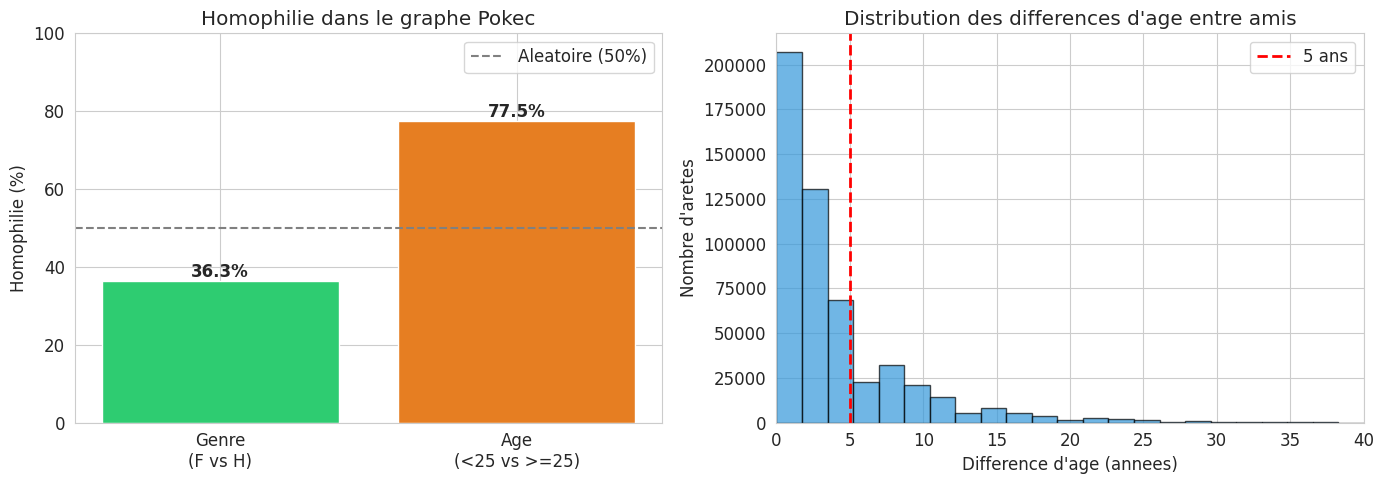

In [9]:
# Visualisation de l'homophilie
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Homophilie genre vs age
homos = [gender_homo * 100, age_homo * 100]
colors = ['#2ecc71', '#e67e22']
bars = axes[0].bar(['Genre\n(F vs H)', 'Age\n(<25 vs >=25)'], homos, color=colors)
axes[0].axhline(50, color='gray', linestyle='--', label='Aleatoire (50%)')
axes[0].set_ylabel('Homophilie (%)')
axes[0].set_title('Homophilie dans le graphe Pokec')
axes[0].set_ylim(0, 100)
axes[0].legend()
for bar, val in zip(bars, homos):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{val:.1f}%', ha='center', fontweight='bold')

# Distribution des differences d'age dans les aretes
age_diffs = np.abs(ages[src] - ages[dst])
axes[1].hist(age_diffs, bins=50, color='#3498db', alpha=0.7, edgecolor='black')
axes[1].axvline(5, color='red', linestyle='--', linewidth=2, label='5 ans')
axes[1].set_xlabel('Difference d\'age (annees)')
axes[1].set_ylabel('Nombre d\'aretes')
axes[1].set_title('Distribution des differences d\'age entre amis')
axes[1].legend()
axes[1].set_xlim(0, 40)

plt.tight_layout()
plt.savefig('fig_homophily.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Split train/val/test (80/10/10)
n = edge_index.shape[1]
perm = torch.randperm(n)
n_val = int(n * 0.1)
n_test = int(n * 0.1)

test_edges = edge_index[:, perm[:n_test]]
val_edges = edge_index[:, perm[n_test:n_test+n_val]]
train_edges = edge_index[:, perm[n_test+n_val:]]

# Negative sampling pour val et test
val_neg = negative_sampling(edge_index, num_nodes=x.shape[0], num_neg_samples=n_val)
test_neg = negative_sampling(edge_index, num_nodes=x.shape[0], num_neg_samples=n_test)

print(f"Train: {train_edges.shape[1]} | Val: {val_edges.shape[1]} | Test: {test_edges.shape[1]}")
print(f"Val neg: {val_neg.shape[1]} | Test neg: {test_neg.shape[1]}")

# Sauvegarder
graph_data = {
    'x': x, 'sensitive': sensitive, 'edge_index': edge_index,
    'train_edges': train_edges, 'val_edges': val_edges, 'test_edges': test_edges,
    'val_neg': val_neg, 'test_neg': test_neg,
    'num_nodes': x.shape[0], 'feature_cols': np.array(FEATURE_COLS),
    'text_cols': TEXT_COLS, 'num_cols': NUM_COLS, 'scaler': scaler,
    'node_ids': np.array(node_ids),
}
torch.save(graph_data, 'graph_data.pt')
print("Sauvegarde: graph_data.pt")

# Sauvegarder les caches pour la robustesse (distribution shift)
profiles.to_pickle('profiles_cache.pkl')
edges_raw.to_pickle('edges_raw_cache.pkl')
print("Sauvegarde: profiles_cache.pkl, edges_raw_cache.pkl")

Train: 423614 | Val: 52951 | Test: 52951
Val neg: 52951 | Test neg: 52951
Sauvegarde: graph_data.pt
Sauvegarde: profiles_cache.pkl, edges_raw_cache.pkl


---
## 3. Modele Baseline - GCN Link Predictor

Architecture : 2 couches GCN (64 -> 128 -> 64) avec dropout, decodeur dot-product.

Pour une paire (u, v), le score de recommandation est : $\text{score}(u, v) = z_u \cdot z_v$ ou $z$ sont les embeddings produits par le GCN.

In [11]:
class GCNLinkPredictor(nn.Module):
    def __init__(self, in_ch, hid_ch, emb_ch, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_ch, hid_ch)
        self.conv2 = GCNConv(hid_ch, emb_ch)
        self.dropout = dropout

    def encode(self, x, edge_index):
        h = F.dropout(F.relu(self.conv1(x, edge_index)), p=self.dropout, training=self.training)
        return self.conv2(h, edge_index)

    def decode(self, z, edge_label_index):
        return (z[edge_label_index[0]] * z[edge_label_index[1]]).sum(dim=-1)

    def forward(self, x, ei, eli):
        return self.decode(self.encode(x, ei), eli)

# Fonctions d'entrainement et evaluation
def train_step(model, x, ei, opt):
    model.train(); opt.zero_grad()
    neg = negative_sampling(ei, num_nodes=x.shape[0], num_neg_samples=ei.shape[1]).to(x.device)
    eli = torch.cat([ei, neg], dim=1)
    lbl = torch.cat([torch.ones(ei.shape[1]), torch.zeros(neg.shape[1])]).to(x.device)
    pred = model(x, ei, eli)
    loss = F.binary_cross_entropy_with_logits(pred, lbl)
    loss.backward(); opt.step()
    return loss.item()

@torch.no_grad()
def eval_link(model, x, ei, pos_e, neg_e):
    model.eval()
    z = model.encode(x, ei)
    ps = model.decode(z, pos_e.to(x.device)).cpu().numpy()
    ns = model.decode(z, neg_e.to(x.device)).cpu().numpy()
    raw = np.concatenate([ps, ns])
    probs = 1 / (1 + np.exp(-raw))
    labels = np.concatenate([np.ones(len(ps)), np.zeros(len(ns))])
    preds = (probs > 0.5).astype(int)
    return dict(auc=roc_auc_score(labels, probs), ap=average_precision_score(labels, probs),
                acc=accuracy_score(labels, preds), f1=f1_score(labels, preds),
                labels=labels, preds=preds, probs=probs, pos_s=ps, neg_s=ns)

print("Modele et fonctions definis.")

Modele et fonctions definis.


In [12]:
# Entrainement
x_dev = x.to(device)
train_edges_dev = train_edges.to(device)

model = GCNLinkPredictor(x.shape[1], 128, 64, 0.5).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

EPOCHS = 200
best_auc, best_state = 0, None
history = {'loss': [], 'val_auc': [], 'val_ap': []}

for ep in range(1, EPOCHS + 1):
    loss = train_step(model, x_dev, train_edges_dev, optimizer)
    history['loss'].append(loss)
    
    if ep % 5 == 0:
        r = eval_link(model, x_dev, train_edges_dev, val_edges, val_neg)
        history['val_auc'].append(r['auc'])
        history['val_ap'].append(r['ap'])
        if r['auc'] > best_auc:
            best_auc = r['auc']
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if ep % 50 == 0:
            print(f"Ep {ep:3d} | Loss {loss:.4f} | Val AUC {r['auc']:.4f} | AP {r['ap']:.4f}")

model.load_state_dict(best_state)
print(f"\nBest Val AUC: {best_auc:.4f}")

Ep  50 | Loss 0.5424 | Val AUC 0.8256 | AP 0.8328
Ep 100 | Loss 0.5209 | Val AUC 0.8484 | AP 0.8574
Ep 150 | Loss 0.5103 | Val AUC 0.8617 | AP 0.8715
Ep 200 | Loss 0.5038 | Val AUC 0.8683 | AP 0.8777

Best Val AUC: 0.8686


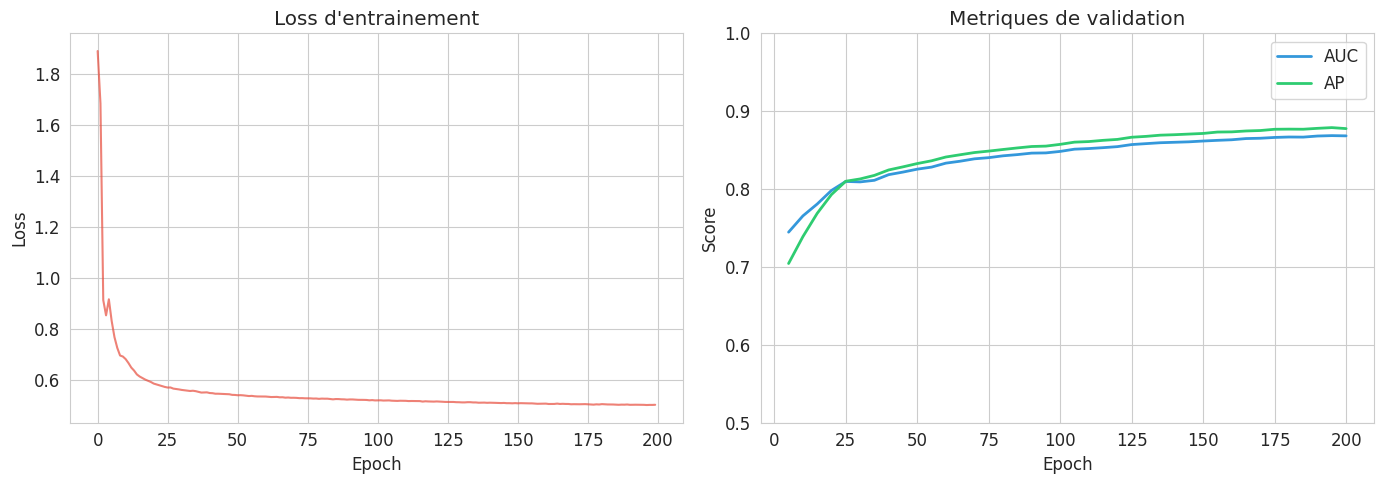

In [13]:
# Courbes d'entrainement
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['loss'], color='#e74c3c', alpha=0.7)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss d\'entrainement')

epochs_eval = list(range(5, EPOCHS+1, 5))
axes[1].plot(epochs_eval, history['val_auc'], label='AUC', color='#3498db', linewidth=2)
axes[1].plot(epochs_eval, history['val_ap'], label='AP', color='#2ecc71', linewidth=2)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score')
axes[1].set_title('Metriques de validation')
axes[1].legend()
axes[1].set_ylim(0.5, 1.0)

plt.tight_layout()
plt.savefig('fig_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Evaluation sur le test set
test_res = eval_link(model, x_dev, train_edges_dev, test_edges, test_neg)
print("=== RESULTATS TEST ===")
print(f"AUC: {test_res['auc']:.4f} | AP: {test_res['ap']:.4f} | Acc: {test_res['acc']:.4f} | F1: {test_res['f1']:.4f}")

# Biais de genre
def gender_bias(pos_e, neg_e, pos_s, neg_s, sensitive):
    s = sensitive.cpu().numpy()
    pp = 1 / (1 + np.exp(-pos_s))
    sg_p, dg_p = s[pos_e[0].numpy()], s[pos_e[1].numpy()]
    same_p = sg_p == dg_p
    m = dict(score_same=pp[same_p].mean(), score_cross=pp[~same_p].mean())
    m['score_gap'] = m['score_same'] - m['score_cross']
    ae = torch.cat([pos_e, neg_e], dim=1)
    ap = 1 / (1 + np.exp(-np.concatenate([pos_s, neg_s])))
    apred = (ap >= 0.5).astype(int)
    sa, da = s[ae[0].numpy()], s[ae[1].numpy()]
    am = sa == da
    m['rec_same'] = apred[am].mean()
    m['rec_cross'] = apred[~am].mean()
    m['rec_gap'] = m['rec_same'] - m['rec_cross']
    m['dp_f'] = apred[sa == 0].mean()
    m['dp_h'] = apred[sa == 1].mean()
    m['dp_gap'] = abs(m['dp_f'] - m['dp_h'])
    return m

bias = gender_bias(test_edges, test_neg, test_res['pos_s'], test_res['neg_s'], sensitive)
print(f"\n=== BIAIS DE GENRE ===")
print(f"Score same: {bias['score_same']:.4f} | cross: {bias['score_cross']:.4f} | gap: {bias['score_gap']:+.4f}")
print(f"Rec same:   {bias['rec_same']:.4f} | cross: {bias['rec_cross']:.4f} | gap: {bias['rec_gap']:+.4f}")
print(f"DP femme:   {bias['dp_f']:.4f} | homme: {bias['dp_h']:.4f} | gap: {bias['dp_gap']:.4f}")

# Sauvegarder le modele
torch.save({
    'model_state': model.state_dict(),
    'test_res': test_res, 'bias': bias,
    'model_config': {'in_ch': x.shape[1], 'hid_ch': 128, 'emb_ch': 64, 'dropout': 0.5},
    'history': history,
}, 'model_baseline.pt')
print("\nSauvegarde: model_baseline.pt")

=== RESULTATS TEST ===
AUC: 0.8673 | AP: 0.8770 | Acc: 0.7214 | F1: 0.7674

=== BIAIS DE GENRE ===
Score same: 0.7839 | cross: 0.7530 | gap: +0.0309
Rec same:   0.6869 | cross: 0.7059 | gap: -0.0190
DP femme:   0.6990 | homme: 0.6964 | gap: 0.0026

Sauvegarde: model_baseline.pt


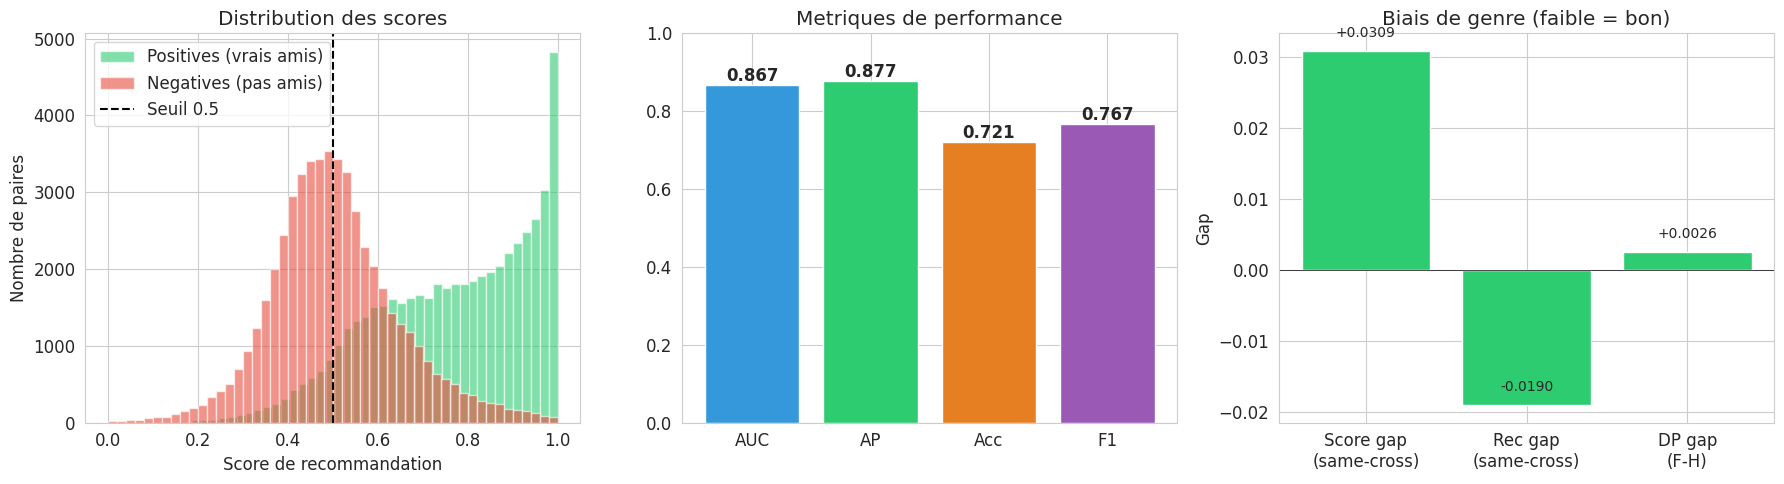

In [15]:
# Visualisation des resultats du baseline
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution des scores
axes[0].hist(test_res['probs'][test_res['labels']==1], bins=50, alpha=0.6, label='Positives (vrais amis)', color='#2ecc71')
axes[0].hist(test_res['probs'][test_res['labels']==0], bins=50, alpha=0.6, label='Negatives (pas amis)', color='#e74c3c')
axes[0].axvline(0.5, color='black', linestyle='--', label='Seuil 0.5')
axes[0].set_xlabel('Score de recommandation'); axes[0].set_ylabel('Nombre de paires')
axes[0].set_title('Distribution des scores')
axes[0].legend()

# Metriques de performance
metrics = ['AUC', 'AP', 'Acc', 'F1']
values = [test_res['auc'], test_res['ap'], test_res['acc'], test_res['f1']]
bars = axes[1].bar(metrics, values, color=['#3498db', '#2ecc71', '#e67e22', '#9b59b6'])
axes[1].set_ylim(0, 1); axes[1].set_title('Metriques de performance')
for bar, val in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.3f}', ha='center', fontweight='bold')

# Biais
bias_names = ['Score gap\n(same-cross)', 'Rec gap\n(same-cross)', 'DP gap\n(F-H)']
bias_vals = [bias['score_gap'], bias['rec_gap'], bias['dp_gap']]
colors_b = ['#e74c3c' if v > 0.05 else '#2ecc71' for v in [abs(v) for v in bias_vals]]
bars = axes[2].bar(bias_names, bias_vals, color=colors_b)
axes[2].axhline(0, color='black', linewidth=0.5)
axes[2].set_title('Biais de genre (faible = bon)')
axes[2].set_ylabel('Gap')
for bar, val in zip(bars, bias_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{val:+.4f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('fig_baseline_results.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Interpretabilite - SHAP

On utilise SHAP (KernelExplainer) pour comprendre quelles features influencent le plus les recommandations.

**Methode** : On fixe un noeud cible et on fait varier les features du noeud source. SHAP mesure la contribution de chaque feature au score de recommandation.

In [18]:
import shap

# Choisir un noeud cible (premier noeud du test set) et un noeud reference
ref_node = int(test_edges[0, 0])
target_node = int(test_edges[1, 0])
print(f"Noeud source (ref): {ref_node} | Noeud cible: {target_node}")

def shap_predict(features):
    """Score de reco quand on modifie les features du noeud source."""
    features_t = torch.tensor(features, dtype=torch.float).to(device)
    scores = np.zeros(len(features))
    for i in range(len(features)):
        xm = x_dev.clone()
        xm[ref_node] = features_t[i]
        with torch.no_grad():
            z = model.encode(xm, train_edges_dev)
            pair = torch.tensor([[ref_node], [target_node]], dtype=torch.long).to(device)
            scores[i] = model.decode(z, pair).sigmoid().item()
    return scores

# Background et samples a expliquer
bg_idx = np.random.choice(x.shape[0], 20, replace=False)
X_bg = x[bg_idx].cpu().numpy()

explain_src = test_edges[0, :30].numpy()
X_explain = x[explain_src].cpu().numpy()

print(f"Background: {X_bg.shape} | Explain: {X_explain.shape}")
print("Calcul SHAP values (peut prendre quelques minutes sur GPU)...")

explainer = shap.KernelExplainer(shap_predict, X_bg)
shap_values = explainer.shap_values(X_explain, nsamples=64)
print("SHAP termine!")

Noeud source (ref): 89961 | Noeud cible: 102583
Background: (20, 64) | Explain: (30, 64)
Calcul SHAP values (peut prendre quelques minutes sur GPU)...


  0%|          | 0/30 [00:00<?, ?it/s]

SHAP termine!


In [19]:
# Analyse SHAP
mean_abs_shap = np.abs(shap_values).mean(axis=0)
ranking = np.argsort(mean_abs_shap)[::-1]

# Sauvegarder
np.savez('shap_results.npz',
         shap_values=shap_values, X_explain=X_explain,
         explain_src=explain_src, feature_cols=np.array(FEATURE_COLS),
         mean_abs_shap=mean_abs_shap, ranking=ranking)
print("Sauvegarde: shap_results.npz")

# Top 20 features
print("\n=== TOP 20 FEATURES PAR IMPORTANCE SHAP ===")
for i, idx in enumerate(ranking[:20]):
    marker = " <<<" if FEATURE_COLS[idx] == 'gender' else ""
    print(f"  {i+1:2d}. {FEATURE_COLS[idx]:42s} | {mean_abs_shap[idx]:.6f}{marker}")

gender_rank = int(np.where(ranking == FEATURE_COLS.index('gender'))[0][0]) + 1
print(f"\n>>> GENDER est au rang {gender_rank}/64 <<<")

Sauvegarde: shap_results.npz

=== TOP 20 FEATURES PAR IMPORTANCE SHAP ===
   1. len_completed_level_of_education           | 0.001148
   2. gender                                     | 0.001085 <<<
   3. has_sign_in_zodiac                         | 0.000995
   4. len_the_idea_of_good_evening               | 0.000491
   5. len_hobbies                                | 0.000473
   6. len_I_am_going_to_concerts                 | 0.000462
   7. has_pets                                   | 0.000370
   8. has_I_am_going_to_concerts                 | 0.000359
   9. has_spoken_languages                       | 0.000355
  10. len_I_like_music                           | 0.000354
  11. has_relation_to_casual_sex                 | 0.000350
  12. len_I_like_movies                          | 0.000348
  13. len_my_passive_sports                      | 0.000330
  14. len_I_mostly_like_listening_to_music       | 0.000325
  15. has_my_partner_should_be                   | 0.000308
  16. len_spoken_langu

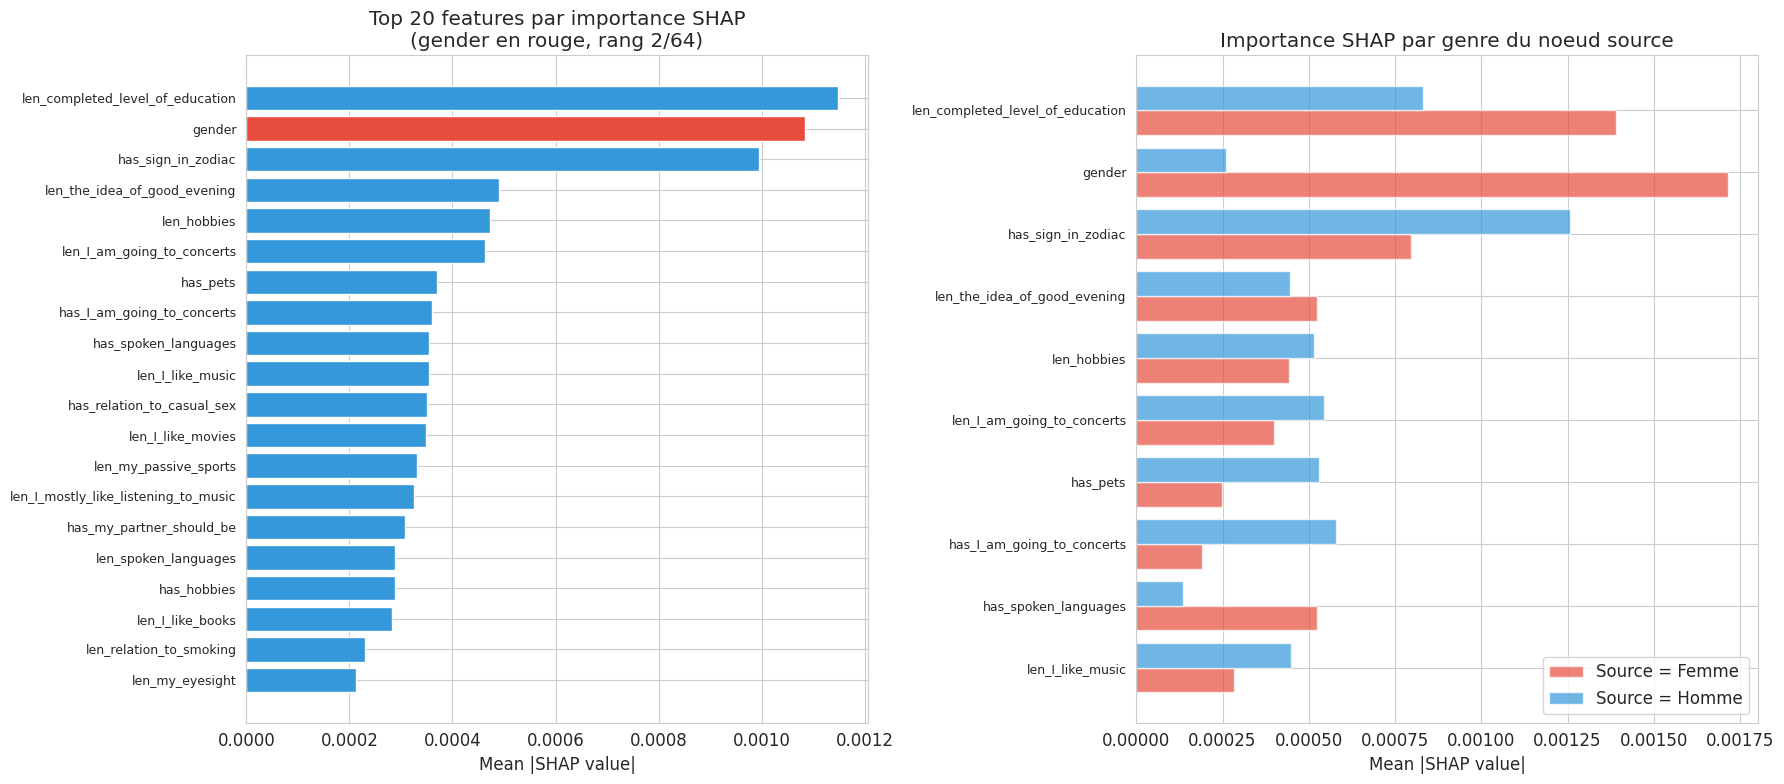

In [20]:
# Visualisation SHAP - Top 20 features
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Bar plot des importances
top_n = 20
top_idx = ranking[:top_n]
top_names = [FEATURE_COLS[i] for i in top_idx]
top_vals = mean_abs_shap[top_idx]
colors_shap = ['#e74c3c' if name == 'gender' else '#3498db' for name in top_names]

axes[0].barh(range(top_n), top_vals[::-1], color=colors_shap[::-1])
axes[0].set_yticks(range(top_n))
axes[0].set_yticklabels(top_names[::-1], fontsize=9)
axes[0].set_xlabel('Mean |SHAP value|')
axes[0].set_title(f'Top {top_n} features par importance SHAP\n(gender en rouge, rang {gender_rank}/64)')

# SHAP par genre du noeud source
src_genders = sensitive[explain_src].numpy()
mask_f = src_genders == 0
mask_h = src_genders == 1

if mask_f.sum() > 0 and mask_h.sum() > 0:
    shap_f = np.abs(shap_values[mask_f]).mean(axis=0)
    shap_h = np.abs(shap_values[mask_h]).mean(axis=0)
    
    top10_idx = ranking[:10]
    top10_names = [FEATURE_COLS[i] for i in top10_idx]
    
    y_pos = np.arange(10)
    axes[1].barh(y_pos - 0.2, shap_f[top10_idx][::-1], 0.4, label='Source = Femme', color='#e74c3c', alpha=0.7)
    axes[1].barh(y_pos + 0.2, shap_h[top10_idx][::-1], 0.4, label='Source = Homme', color='#3498db', alpha=0.7)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(top10_names[::-1], fontsize=9)
    axes[1].set_xlabel('Mean |SHAP value|')
    axes[1].set_title('Importance SHAP par genre du noeud source')
    axes[1].legend()

plt.tight_layout()
plt.savefig('fig_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()